# UniRemington - Cali<br>Facultad de Ingeniería - Línea de Énfasis III: Ciencia de Datos y Machine Learning<br>(ↄ) Diego Fernando Marin, 2026-2

## Datos del Estudiante

**Código**: 1143875526<br>
**Nombre**: Javier Jose Gaviria Morales<br>
**Correo**: javier.gaviria.5526@miremington.edu.co

# Taller #1 - Encuesta TV

## 0. Introducción

### ¿Qué vas a hacer en este taller?

Vas a realizar un **análisis exploratorio de datos (EDA)** sobre una encuesta de hábitos de televisión: quién ve qué, cuántas horas y cuánto paga por sus suscripciones. Lo harás con las dos librerías base del ecosistema de ciencia de datos en Python: **Pandas** (manipulación de tablas) y **Matplotlib** (gráficos).

### Alcance

Al terminar serás capaz de:

1. Inspeccionar un conjunto de datos nuevo (tamaño, tipos, valores faltantes).
2. Filtrar, contar, agrupar y ordenar con operaciones *vectorizadas* (sin recorrer filas con `for`).
3. Elegir y construir el gráfico adecuado para cada tipo de pregunta.
4. Contrastar hipótesis simples (¿hay diferencia entre hombres y mujeres?) y detectar *outliers*.
5. **Comunicar con honestidad** lo que los datos permiten (y no permiten) concluir.

## 1. Contexto del problema

Imagina que trabajas para un canal regional o una plataforma de *streaming* que quiere entender mejor a su audiencia. Se aplicó una encuesta corta a **68 personas** y la gerencia quiere respuestas a preguntas como:

- ¿Quiénes son los encuestados (edad, género)?
- ¿Qué canales son los más queridos y **quién los prefiere**? Esto orienta qué contenidos comprar o promocionar.
- ¿Ven más televisión los jóvenes o los adultos? Esto orienta **en qué franja** y con qué formato publicar.
- ¿Cuánto pagan por sus suscripciones y **qué tipo de persona paga más**? Esto orienta la política de precios.

**¿Por qué EDA y no directamente un modelo?** Porque antes de predecir hay que *entender*: un análisis exploratorio revela errores en los datos, patrones y preguntas nuevas, y evita construir modelos sobre supuestos falsos.

### Diccionario de datos

| Variable | Descripción | Tipo esperado |
|---|---|---|
| `nombre` | Nombre del encuestado | texto |
| `edad` | Edad en años | entero |
| `genero` | `M` (masculino) o `F` (femenino) | categórica |
| `canal_fav1`, `canal_fav2`, `canal_fav3` | Primer, segundo y tercer canal favorito | texto |
| `horas` | Horas de consumo de TV (horas x día) | entero |
| `costo_mes` | Costo mensual de suscripciones (pesos colombianos) | entero |

## 2. Preparación del entorno

Esta celda ya está completa: es el **ejemplo resuelto** que te muestra el estilo de las siguientes. Ejecútala y lee cada línea.

In [ ]:
# 1) Descarga el archivo y lo guarda como encuesta_tv.csv (en Colab/Jupyter, el "!" ejecuta un comando de consola)
!wget --no-verbose -O encuesta_tv.csv https://paste.c-net.org/WimpsPaolo

2026-11-13 21:14:41 URL:https://paste.c-net.org/WimpsPaolo [3134/3134] -> "encuesta_tv.csv" [1]


In [ ]:
# 2) Importamos las librerías con sus alias convencionales
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [ ]:
# 3) Cargamos el CSV. OJO: el separador NO es coma, es una barra vertical "|"
df = pd.read_csv('encuesta_tv.csv', sep='|')

> **Teoría — separadores.** `read_csv` asume por defecto que las columnas están separadas por coma. Si el archivo usa otro carácter y no lo indicas con `sep=`, obtendrás **una sola columna** con todo pegado. Si te ocurre, ese es el primer sospechoso.

> **Alternativa sin `wget`:** `pd.read_csv('https://paste.c-net.org/WimpsPaolo', sep='|')` lee directamente desde la URL.

## Parte 1 — Primer contacto con los datos (Pasos 1–4)

> **Teoría.** Antes de calcular nada, un analista responde tres preguntas: *¿cuánto hay?* (dimensiones), *¿de qué tipo es cada columna?* (tipos y nulos) y *¿cómo se ve?* (muestras del inicio **y** del final; el final puede revelar registros agregados más tarde con otro formato).


### Paso 1. ¿Cuántos registros (filas) y variables (columnas) hay?

**Lógica:** `shape` devuelve una *tupla* `(filas, columnas)`.

In [ ]:
# Obtén las dimensiones del DataFrame.
# Pista: shape es un ATRIBUTO (no lleva paréntesis).
df.shape

(68, 8)

### Paso 2. ¿Cuáles son las variables, sus nombres y tipos?

**Lógica:** `info()` resume nombre, **cantidad de valores no nulos** y tipo (`dtype`) de cada columna. Compara el número de no nulos con el total de filas: ahí se descubren los datos faltantes.

In [ ]:
# Muestra el resumen estructural del DataFrame.
# Pista: info() es un MÉTODO (sí lleva paréntesis) e imprime directamente.
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 68 entries, 0 to 67
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   nombre      68 non-null     object
 1   edad        68 non-null     int64 
 2   genero      68 non-null     object
 3   canal_fav1  68 non-null     object
 4   canal_fav2  68 non-null     object
 5   canal_fav3  67 non-null     object
 6   horas       68 non-null     int64 
 7   costo_mes   68 non-null     int64 
dtypes: int64(3), object(5)
memory usage: 4.4+ KB


### Paso 3. Muestra las primeras 10 filas de los datos.

In [ ]:
# Muestra las 10 primeras filas.
# Pista: head(n) recibe el número de filas.
df.head(10)

,nombre,edad,genero,canal_fav1,canal_fav2,canal_fav3,horas,costo_mes
0,orlando,35,M,RCN,Telepacifico,HBO+,4,25000
1,jennifer,18,F,Caracol,RCN,Netflix,8,18000
2,julián,33,M,CNN,Star+,Disney+,5,23000
3,luisa,25,F,RCN,Caracol,Cinemax,6,15000
4,marcelo,16,M,Boomerang,Cartoon Network,Disney+,9,20000
5,guillermo,41,M,ESPN,ESPN2,Fox Sports,10,25000
6,stephany,11,F,Disney+,Star+,Amazon Prime,6,19000
7,mariana,32,F,Star+,HBO+,Paramount+,4,21000
8,juan,28,M,Fox,HBO+,Netflix,7,22000
9,andrea,20,F,Caracol,RCN,Netflix,5,19000


### Paso 4. Muestra las últimas 10 filas de los datos.

In [ ]:
# Muestra las 10 últimas filas.
# Pista: es el método "hermano" de head().
df.tail(10)

,nombre,edad,genero,canal_fav1,canal_fav2,canal_fav3,horas,costo_mes
58,paola,25,F,ESPN,ESPN2,Fox Sports,4,21000
59,juanita maria,34,F,HBO+,Netflix,Amazon Prime,6,23000
60,carlos andres,32,M,CNN,BBC,Discovery,5,24000
61,lina,23,F,HBO+,Netflix,Amazon Prime,7,20000
62,felipe andres,35,M,ESPN,ESPN2,Fox Sports,6,22000
63,maria,26,F,Netflix,HBO+,Disney+,5,21000
64,andres felipe,36,M,RCN,Caracol,Telepacifico,7,20000
65,juliana,24,F,ESPN,ESPN2,Fox Sports,4,22000
66,pablo,37,M,HBO+,Netflix,Amazon Prime,6,23000
67,juana,29,F,CNN,BBC,Discovery,5,21000


### Evaluación — Parte 1

- **E1.1 (conceptual).** En la salida de `info()` una columna muestra menos valores no nulos que las demás. ¿Cuál es y qué significa?

**Respuesta:** La columna `canal_fav3` tiene 67 valores no nulos, mientras que las demás tienen 68. Significa que hay un dato faltante (NaN): una persona no respondió su tercer canal favorito.

- **E1.2 (conceptual).** ¿Por qué `df.shape` se escribe sin paréntesis y `df.info()` con ellos?

**Respuesta:** `shape` es un atributo, es decir, un dato que ya está guardado en el DataFrame (la tupla filas, columnas), por eso no lleva paréntesis. `info()` es un método, o sea una función que ejecuta una acción para mostrar el resumen, por eso lleva paréntesis.

- **E1.3 (código).** Obtén de una sola vez las estadísticas descriptivas (conteo, media, desviación, mínimo, cuartiles, máximo) de las columnas numéricas.

In [ ]:
# Reto E1.3 — Pista: existe un método cuyo nombre en inglés significa "describir".
df.describe()

,edad,horas,costo_mes
count,68.000000,68.000000,68.000000
mean,29.882353,6.102941,21470.588235
std,11.033909,1.497657,2215.754905
min,11.000000,4.000000,15000.000000
25%,21.750000,5.000000,20000.000000
50%,29.000000,6.000000,22000.000000
75%,37.000000,7.000000,23000.000000
max,53.000000,10.000000,27000.000000


## Parte 2 — Valores únicos, estadísticas y conteos (Pasos 5–8)

> **Teoría.** Tres herramientas que usarás todo el curso:
> - `Serie.unique()` → los valores distintos (como arreglo).
> - `Serie.nunique()` → **cuántos** valores distintos hay (ignora `NaN`).
> - `Serie.value_counts()` → cuántas veces aparece cada valor, ordenado de mayor a menor.


### Paso 5. ¿Cuáles son los nombres únicos de las personas encuestadas?

In [ ]:
# Obtén los nombres distintos de la columna 'nombre'.
# Pista: selecciona la columna con df['nombre'] y aplica el método de valores únicos.
df['nombre'].unique()

array(['orlando', 'jennifer', 'julián', 'luisa', 'marcelo', 'guillermo',
       'stephany', 'mariana', 'juan', 'andrea', 'carlos', 'valentina',
       'diego', 'camila', 'felipe', 'ana', 'oscar', 'natalia', 'daniel',
       'sara', 'luis', 'catalina', 'pedro', 'alejandra', 'rodrigo',
       'laura', 'manuel', 'andres', 'patricia', 'ana maria', 'jose',
       'andres felipe', 'santiago', 'carolina', 'diana', 'andres david',
       'sergio', 'margarita', 'juanita', 'carlos alberto',
       'andrea carolina', 'carlos enrique', 'marcela', 'lucas',
       'patricia andrea', 'pedro jose', 'luis alberto', 'andrea maria',
       'jose luis', 'carla', 'miguel', 'luz', 'juan pablo', 'camilo',
       'andrea patricia', 'roberto', 'claudia', 'alejandro', 'paola',
       'juanita maria', 'carlos andres', 'lina', 'felipe andres', 'maria',
       'juliana', 'pablo', 'juana'], dtype=object)

### Paso 6. ¿Cuántos canales únicos hay y cuáles son?

**Lógica:** los canales están repartidos en **tres columnas**. Para contarlos como un solo conjunto primero hay que *apilar* las tres columnas en una sola Serie con `pd.concat([...])`.


In [ ]:
# 1. Apila canal_fav1, canal_fav2 y canal_fav3 en una sola Serie (guárdala en la variable 'canales').
# 2. Muestra los canales distintos con unique().
# 3. Cuenta cuántos hay con nunique() y compara con len(canales.unique()).
canales = pd.concat([df['canal_fav1'], df['canal_fav2'], df['canal_fav3']])
print(canales.unique())
print(canales.nunique())
print(len(canales.unique()))

['RCN' 'Caracol' 'CNN' 'Boomerang' 'ESPN' 'Disney+' 'Star+' 'Fox'
 'Teleantioquia' 'Warner' 'Netflix' 'HBO+' 'Cartoon Network' 'Disney'
 'Discovery' 'Telepacifico' 'ESPN2' 'TNT' 'BBC' 'Fox Sports' 'NatGeo'
 'Cinemax' 'Amazon Prime' 'Paramount+' 'Sony' 'GolTV' 'Nickelodeon'
 'History' nan]
28
29


> **Advertencia — `NaN` es un valor.** `unique()` **incluye** el valor faltante (`NaN`) como si fuera un canal; `nunique()` lo ignora. Si cuentas con `len(unique())` obtendrás un canal "fantasma".

### Paso 7. ¿Cuál es el promedio de edad?

In [ ]:
# Calcula la edad promedio.
# Pista: df['edad'] + método de la media.
# Exploración extra: prueba .min(), .max(), .median(), .sum(), .count()
df['edad'].mean()

np.float64(29.88235294117647)

> Los métodos de resumen de una Serie incluyen `.min()`, `.max()`, `.median()`, `.sum()`, `.count()` y `.value_counts()`. (En el comentario del cuaderno original aparece escrito `values_count`, que **no existe**: el nombre correcto es `value_counts`.)

### Paso 8. ¿Cuántos encuestados son hombres y cuántas mujeres?

Resuelve el conteo de DOS formas.

In [ ]:
# Forma A: value_counts() sobre la columna 'genero'.
df['genero'].value_counts()

,count
genero,
M,35
F,33


In [ ]:
# Forma B: df.groupby('genero') seguido de .size()
df.groupby('genero').size()

,0
genero,
F,33
M,35


### Evaluación — Parte 2

- **E2.1 (conceptual).** En el Paso 6, ¿por qué `len(canales.unique())` y `canales.nunique()` dan resultados distintos? ¿Cuál es la cifra correcta de canales?

**Respuesta:** `unique()` cuenta el NaN como si fuera un valor más (29), mientras que `nunique()` lo ignora (28). La cifra correcta de canales es 28, porque el NaN es un dato faltante y no un canal.

- **E2.2 (código).** `nombre` tiene menos valores únicos que filas. Encuentra **todas** las filas cuyo nombre está repetido. ¿Son la misma persona?

In [ ]:
# Pista E2.2 -> duplicated(keep=False) marca TODAS las filas repetidas, no solo la segunda aparición.
df[df['nombre'].duplicated(keep=False)]
# Son dos personas distintas: 'andres felipe' de 15 años y otro de 36 años (cambian la edad, los canales y las horas).

,nombre,edad,genero,canal_fav1,canal_fav2,canal_fav3,horas,costo_mes
31,andres felipe,15,M,Discovery,NatGeo,History,9,20000
64,andres felipe,36,M,RCN,Caracol,Telepacifico,7,20000


- **E2.3 (código).** Calcula el **porcentaje** de hombres y de mujeres (no la cantidad).

In [ ]:
# Pista E2.3 -> value_counts() tiene un parámetro que devuelve proporciones (multiplica por 100).
df['genero'].value_counts(normalize=True) * 100

,proportion
genero,
M,51.470588
F,48.529412


- **E2.4 (código + conceptual).** Calcula la **mediana** de edad y compárala con la media. ¿Qué te dice la diferencia?

In [ ]:
# Pista E2.4 -> .median()
print(df['edad'].median())
print(df['edad'].mean())
# La mediana (29.0) y la media (29.88) son casi iguales: la distribución de edades es bastante simétrica y no hay valores extremos que la distorsionen.

29.0
29.88235294117647


## Parte 3 — Filtros y rankings de frecuencia (Pasos 9–11)


> **Teoría — filtrado booleano.** Una condición sobre una columna (`df['edad'] >= 18`) produce una Serie de `True/False`, llamada **máscara**. Al pasarla a `df[...]` quedan solo las filas `True`. Se combinan con `&` (y), `|` (o) y `~` (no), **cada condición entre paréntesis**.

### Paso 9. Muestra los nombres de los hombres mayores de edad

In [ ]:
# 1. Crea la máscara 'filtro' combinando (genero == 'M') y (edad >= 18) con &.
filtro = (df['genero'] == 'M') & (df['edad'] >= 18)

In [ ]:
# 2. Aplica la máscara a df y muestra solo la columna 'nombre'.
df[filtro]['nombre']

,nombre
0,orlando
2,julián
5,guillermo
8,juan
10,carlos
12,diego
14,felipe
16,oscar
18,daniel
20,luis


> **Antipatrón — no recorras filas con `for`.** El cuaderno original muestra una versión con `df.iterrows()` y la marca como lo que **NO** se debe hacer: obliga a Python a procesar fila por fila, mientras que la máscara booleana opera sobre toda la columna en código compilado. Con 68 filas no notarás la diferencia; con 10 millones, sí.

In [ ]:
# Esto es lo que NO se debe hacer, no es optimo! obliga a usar filas:
for index, datos in df[['nombre', 'genero', 'edad']].iterrows():
    if datos.genero == 'M' and datos.edad >= 18:
        print(datos.nombre)

orlando
julián
guillermo
juan
carlos
diego
felipe
oscar
daniel
luis
pedro
rodrigo
jose
sergio
carlos alberto
carlos enrique
pedro jose
luis alberto
jose luis
miguel
juan pablo
camilo
roberto
alejandro
carlos andres
felipe andres
andres felipe
pablo


### Paso 10. ¿Cuáles son los 3 canales favoritos más comunes?

In [ ]:
# 1. Apila las tres columnas de canales (como en el Paso 6).
canales = pd.concat([df['canal_fav1'], df['canal_fav2'], df['canal_fav3']])

In [ ]:
# 2. Cuenta la frecuencia de cada canal con value_counts().
conteo = canales.value_counts()
conteo

,count
HBO+,25
Netflix,21
RCN,15
ESPN,15
Caracol,14
Fox Sports,14
Amazon Prime,14
Disney+,10
ESPN2,9
Discovery,8


In [ ]:
# 3. Quédate con los 3 primeros con head(3).
conteo.head(3)

,count
HBO+,25
Netflix,21
RCN,15


### Paso 11. ¿Cuál es el canal favorito (`canal_fav1`) más popular entre hombres y entre mujeres?

In [ ]:
# Agrupa por 'genero', toma la columna 'canal_fav1' y cuenta con value_counts().
# Pista: df.groupby(...)[...].value_counts()
# Reto extra: muestra solo los 3 primeros de cada género (investiga .groupby(level=0).head(3)).
conteo_genero = df.groupby('genero')['canal_fav1'].value_counts()
conteo_genero.groupby(level=0).head(3)

genero  canal_fav1     
F       HBO+                9
        Caracol             5
        CNN                 4
M       ESPN               12
        HBO+                5
        Cartoon Network     4
Name: count, dtype: int64

### Evaluación — Parte 3

- **E3.1 (conceptual).** ¿Por qué en el Paso 9 se escribe `&` y no `and`, y por qué cada condición va entre paréntesis?

**Respuesta:** Se usa `&` porque `and` compara un solo valor True/False y no sirve para comparar Series fila por fila (da error). El `&` trabaja elemento por elemento. Cada condición va entre paréntesis porque `&` se evalúa antes que `==` o `>=`, y sin paréntesis la operación saldría mal.

- **E3.2 (código).** ¿Cuántas **mujeres menores de edad** hay y cómo se llaman?


In [ ]:
menores_f = df[(df['genero'] == 'F') & (df['edad'] < 18)]
print(len(menores_f))
menores_f['nombre']

3


,nombre
6,stephany
29,ana maria
38,juanita


- **E3.3 (código + conceptual).** Muestra el **top 5** de canales del Paso 10. ¿Qué observas en el tercer puesto? ¿Qué problema crea `head(3)`?


In [ ]:
conteo.head(5)

,count
HBO+,25
Netflix,21
RCN,15
ESPN,15
Caracol,14


**Respuesta:** En el tercer puesto hay un empate: RCN y ESPN tienen 15 menciones cada uno. El problema de `head(3)` es que corta de forma arbitraria y deja por fuera a ESPN, que debería aparecer igual que RCN.

- **E3.4 (código).** El Paso 11 solo mira `canal_fav1`. Repite el análisis considerando **los tres** canales favoritos. *Pista:* `df.melt(id_vars='genero', value_vars=[...], value_name='canal')` convierte tres columnas en una sola columna larga. ¿Cambia la conclusión?

In [ ]:
largo = df.melt(id_vars='genero', value_vars=['canal_fav1', 'canal_fav2', 'canal_fav3'], value_name='canal')
largo.groupby('genero')['canal'].value_counts().groupby(level=0).head(3)
# La conclusión no cambia: las mujeres siguen con HBO+ en primer lugar y los hombres con ESPN.

genero  canal     
F       HBO+          16
        Netflix       14
        Caracol       11
M       ESPN          13
        Fox Sports    12
        HBO+           9
Name: count, dtype: int64

## Parte 4 — Relaciones entre variables y extremos (Pasos 12–14)

> **Teoría — correlación de Pearson.** `Serie_a.corr(Serie_b)` mide la **relación lineal** entre dos variables numéricas, entre −1 y +1:
> - cercana a **+1**: cuando una sube, la otra tiende a subir;
> - cercana a **−1**: cuando una sube, la otra tiende a bajar;
> - cercana a **0**: *no hay relación lineal* (¡pero puede haber otra forma de relación!).
>
> **Correlación no implica causalidad.**


### Paso 12. ¿Hay relación entre la edad y las horas de consumo de TV?

In [ ]:
# Calcula el coeficiente de correlación entre 'edad' y 'horas'.
# Interpreta el valor en una línea de comentario: ¿fuerte, débil, nula?
print(df['edad'].corr(df['horas']))
# La correlación es cercana a 0 (aprox. -0.03): es nula, no hay relación lineal entre la edad y las horas de TV.

-0.027255358787632557


### Paso 13. ¿Cuál es el costo promedio mensual de suscripciones?

In [ ]:
# Calcula el promedio de la columna 'costo_mes'.
df['costo_mes'].mean()

np.float64(21470.58823529412)

### Paso 14. ¿Cuál es el encuestado más joven y cuál el de mayor edad?

**Lógica:** no basta con el valor mínimo; queremos **quién** es. `idxmin()` / `idxmax()` devuelven la *etiqueta de la fila* donde ocurre el mínimo/máximo, y con `.loc[...]` recuperas esa fila completa.


In [ ]:
# Encuentra la fila del más joven y la fila del mayor.
# Pista: df.loc[df['edad'].idxmin()]  y  df.loc[df['edad'].idxmax()]
# Alternativa: df.sort_values('edad') y mira la primera y la última fila.
print(df.loc[df['edad'].idxmin()])
print(df.loc[df['edad'].idxmax()])

nombre            stephany
edad                    11
genero                   F
canal_fav1         Disney+
canal_fav2           Star+
canal_fav3    Amazon Prime
horas                    6
costo_mes            19000
Name: 6, dtype: object
nombre         jose luis
edad                  53
genero                 M
canal_fav1          ESPN
canal_fav2    Fox Sports
canal_fav3           NaN
horas                 10
costo_mes          27000
Name: 48, dtype: object


### Evaluación — Parte 4

- **E4.1 (conceptual).** Si en el Paso 12 obtuviste una correlación cercana a 0, ¿puedes afirmar que la edad **no influye** en las horas de TV? Justifica.


**Respuesta:** No. La correlación de Pearson solo mide relaciones lineales (en línea recta). Un valor cercano a 0 dice que no hay relación lineal, pero puede existir otro tipo de relación. Por eso se verifica en E4.2.

- **E4.2 (código).** Verifica tu respuesta anterior: compara el promedio de horas de los **menores de 18** contra los **adultos**. *Pista:* `df.groupby(df['edad'] < 18)['horas'].mean()`.


In [ ]:
df.groupby(df['edad'] < 18)['horas'].mean()
# Los menores de 18 ven más horas en promedio (7.4) que los adultos (5.88): sí hay diferencia, aunque la correlación lineal sea casi 0.

,horas
edad,
False,5.87931
True,7.40000


- **E4.3 (código).** Calcula la correlación entre `edad` y `costo_mes`. ¿Qué tan fuerte es?


In [ ]:
df['edad'].corr(df['costo_mes'])
# La correlación es 0.65: positiva y de fuerza moderada-alta (a mayor edad, mayor costo).

np.float64(0.6500215115262994)

- **E4.4 (código).** Obtén la edad mínima y máxima **por género** en una sola instrucción (`groupby` + `agg`).


In [ ]:
df.groupby('genero')['edad'].agg(['min', 'max'])

,min,max
genero,,
F,11,51
M,12,53


## Parte 5 — Visualización básica (Pasos 15–18)

> **Teoría — ¿qué gráfico para qué pregunta?**
>
> | Pregunta | Gráfico |
> |---|---|
> | Cuántos hay en cada categoría | Barras |
> | Qué parte del total es cada categoría (pocas categorías) | Pie / torta |
> | Cómo se distribuye una variable numérica | Barras sobre conteos o histograma |
> | Cómo se relacionan dos variables numéricas | Dispersión (*scatter*) |
> | Composición dentro de cada categoría | Barras apiladas |
>
> **Regla de oro:** todo gráfico lleva **título**, **etiquetas de ejes** y, si hay varias series, **leyenda**.


### Paso 15. Gráfico de barras: distribución de edades

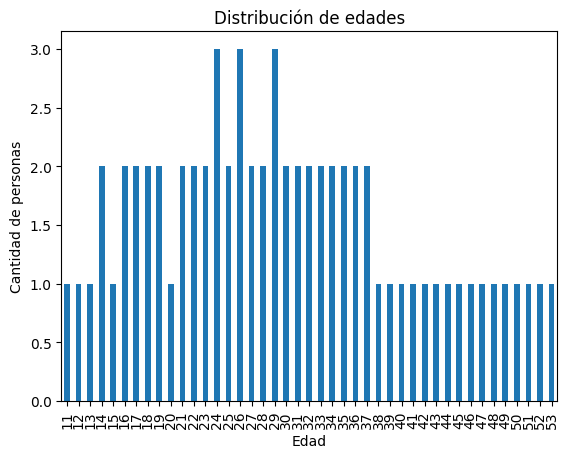

In [ ]:
# 1. Cuenta cuántas personas hay de cada edad (value_counts) y ordena por edad (sort_index).

# 2. Grafica con .plot(kind='bar').

# 3. Añade título y etiquetas de ejes con plt.title(), plt.xlabel(), plt.ylabel().

# 4. Cierra con plt.show().
edades = df['edad'].value_counts().sort_index()
edades.plot(kind='bar')
plt.title('Distribución de edades')
plt.xlabel('Edad')
plt.ylabel('Cantidad de personas')
plt.show()

### Paso 16. Gráfico de pie: distribución de géneros


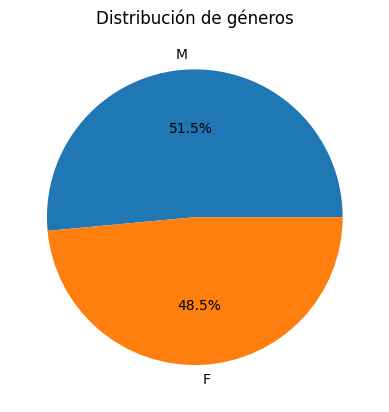

In [ ]:
# Usa los conteos de género y grafica con .plot(kind='pie', autopct='%1.1f%%')
# (autopct imprime el porcentaje sobre cada porción). Agrega un título.
generos = df['genero'].value_counts()
generos.plot(kind='pie', autopct='%1.1f%%')
plt.title('Distribución de géneros')
plt.ylabel('')
plt.show()

### Paso 17. Barras apiladas: los 3 canales favoritos por género

**Lógica:** necesitas una tabla con canales en las filas y géneros en las columnas (`pd.crosstab`), restringida a los 3 canales más frecuentes, y luego graficarla con `stacked=True`.


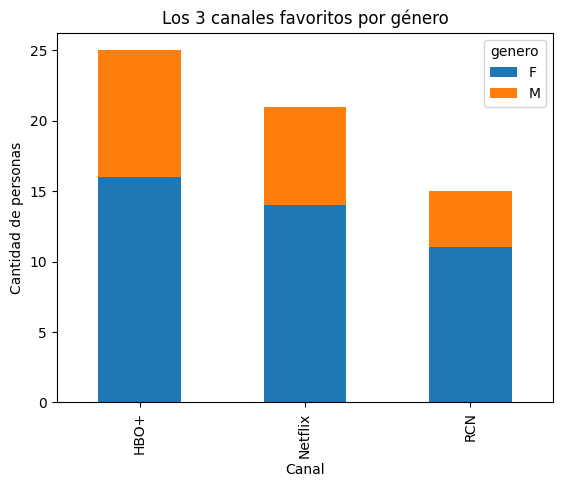

In [ ]:
# 1. Convierte las 3 columnas de canales en una sola columna larga con df.melt(...) (como en E3.4).

# 2. Determina los 3 canales más frecuentes.

# 3. Construye la tabla con pd.crosstab(largo['canal'], largo['genero']) y filtra esos 3 con .loc[...].

# 4. Grafica con .plot(kind='bar', stacked=True) y agrega título y etiquetas.
largo = df.melt(id_vars='genero', value_vars=['canal_fav1', 'canal_fav2', 'canal_fav3'], value_name='canal')
top3 = largo['canal'].value_counts().head(3).index
tabla = pd.crosstab(largo['canal'], largo['genero']).loc[top3]
tabla.plot(kind='bar', stacked=True)
plt.title('Los 3 canales favoritos por género')
plt.xlabel('Canal')
plt.ylabel('Cantidad de personas')
plt.show()

### Paso 18. Dispersión: edad vs. horas de consumo de TV


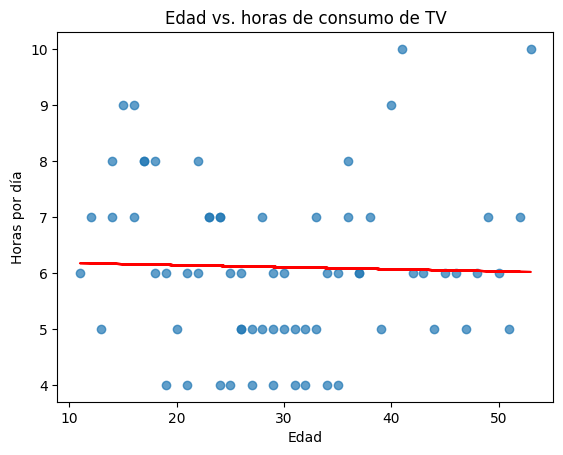

In [ ]:
# 1. Usa plt.scatter(x, y) con x = edad e y = horas (alpha=0.7 ayuda cuando los puntos se superponen).
# 2. Reto extra: dibuja la línea de tendencia con np.polyfit(x, y, 1) y plt.plot(...).
x = df['edad']
y = df['horas']
plt.scatter(x, y, alpha=0.7)
m, b = np.polyfit(x, y, 1)
plt.plot(x, m * x + b, color='red')
plt.title('Edad vs. horas de consumo de TV')
plt.xlabel('Edad')
plt.ylabel('Horas por día')
plt.show()

### Evaluación — Parte 5

- **E5.1 (conceptual).** El gráfico del Paso 15 tiene muchas barras muy delgadas (una por cada edad distinta). ¿Qué gráfico resumiría mejor la distribución y por qué?


**Respuesta:** Un histograma, porque agrupa las edades en intervalos (bins) y muestra mejor la forma de la distribución, en lugar de tener una barra delgada por cada edad.

- **E5.2 (conceptual).** ¿En qué situaciones un gráfico de pie es mala idea?


**Respuesta:** Un gráfico de pie es mala idea cuando hay muchas categorías, cuando las porciones tienen tamaños parecidos y es difícil compararlas, o cuando los datos no son partes de un total.

- **E5.3 (código).** Construye un histograma de `horas`.


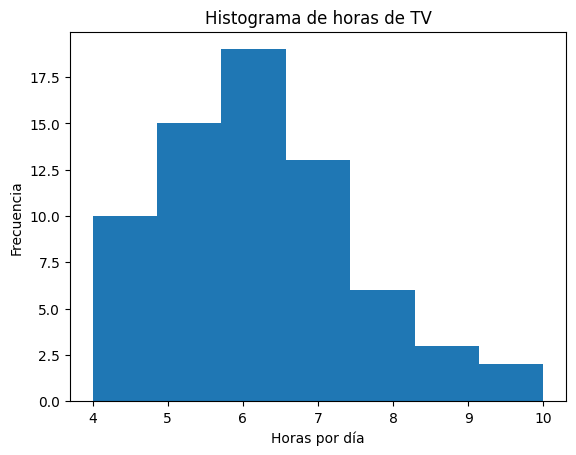

In [ ]:
# Reto E5.3 — Pista: .plot(kind='hist', bins=7)  o  plt.hist(...)
df['horas'].plot(kind='hist', bins=7)
plt.title('Histograma de horas de TV')
plt.xlabel('Horas por día')
plt.ylabel('Frecuencia')
plt.show()

- **E5.4 (conceptual).** Mirando el gráfico del Paso 17: ¿qué canal de los tres tiene más aficionadas que aficionados? ¿Y la relación sigue igual para todos?


**Respuesta:** Los tres canales (HBO+, Netflix y RCN) tienen más aficionadas que aficionados: HBO+ 16 mujeres y 9 hombres, Netflix 14 y 7, RCN 11 y 4. La relación no es igual en todos: en RCN la diferencia es mayor (casi 3 a 1) y en HBO+ es menor.

## Parte 6 — Rankings y agrupaciones (Pasos 19, 20, 22, 23)

> **Teoría — tres patrones muy frecuentes.**
> 1. **Ranking:** `df.nlargest(n, 'col')` / `df.nsmallest(n, 'col')` (equivale a ordenar y tomar los primeros).
> 2. **Discretizar:** `pd.cut(serie, bins=[...], labels=[...])` convierte una variable numérica en **grupos por rangos**. Los intervalos son **cerrados a la derecha**: `(9, 20]` incluye el 20 y excluye el 9.
> 3. **Agrupar y resumir:** `df.groupby('grupo')['col'].mean()`.


### Paso 19. Los 5 encuestados con mayor costo mensual (y grafícalos)


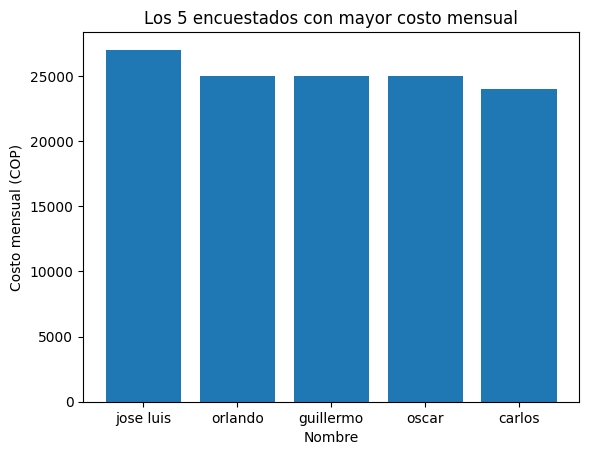

In [ ]:
# 1. Obtén las 5 filas con mayor 'costo_mes' usando nlargest.
# 2. Grafica un diagrama de barras con los nombres en el eje x y el costo en el eje y.
top5_costo = df.nlargest(5, 'costo_mes')
plt.bar(top5_costo['nombre'], top5_costo['costo_mes'])
plt.title('Los 5 encuestados con mayor costo mensual')
plt.xlabel('Nombre')
plt.ylabel('Costo mensual (COP)')
plt.show()

### Paso 20. Costo promedio mensual por grupo de edad (10-20, 21-30, ...)


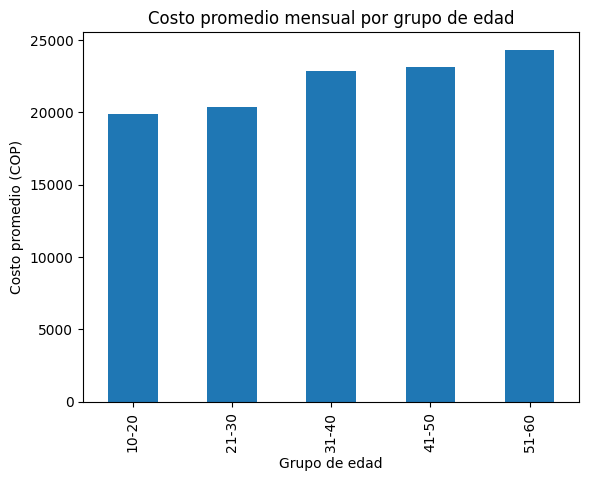

In [ ]:
# 1. Define los límites de los grupos (bins) y sus etiquetas. Pista: bins = [9, 20, 30, 40, 50, 60]
# 2. Crea la columna 'grupo_edad' con pd.cut.
# 3. Calcula el costo promedio por grupo con groupby(...)['costo_mes'].mean()
#    (usa observed=True para evitar un aviso de Pandas con categorías).
# 4. Grafícalo como barras.
bins = [9, 20, 30, 40, 50, 60]
etiquetas = ['10-20', '21-30', '31-40', '41-50', '51-60']
df['grupo_edad'] = pd.cut(df['edad'], bins=bins, labels=etiquetas)
costo_grupo = df.groupby('grupo_edad', observed=True)['costo_mes'].mean()
costo_grupo.plot(kind='bar')
plt.title('Costo promedio mensual por grupo de edad')
plt.xlabel('Grupo de edad')
plt.ylabel('Costo promedio (COP)')
plt.show()

### Paso 22. Los 3 canales más populares entre los de 30 años o más


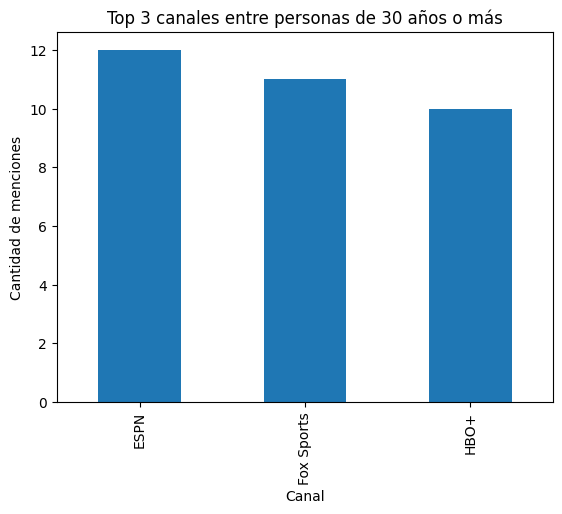

In [ ]:
# 1. Filtra df para quedarte con edad >= 30.
# 2. Apila sus tres columnas de canales y cuenta con value_counts().
# 3. Toma el top 3 y grafícalo.
mayores30 = df[df['edad'] >= 30]
canales30 = pd.concat([mayores30['canal_fav1'], mayores30['canal_fav2'], mayores30['canal_fav3']])
top3_30 = canales30.value_counts().head(3)
top3_30.plot(kind='bar')
plt.title('Top 3 canales entre personas de 30 años o más')
plt.xlabel('Canal')
plt.ylabel('Cantidad de menciones')
plt.show()

### Paso 23. Barras horizontales: los 5 encuestados con más horas de TV


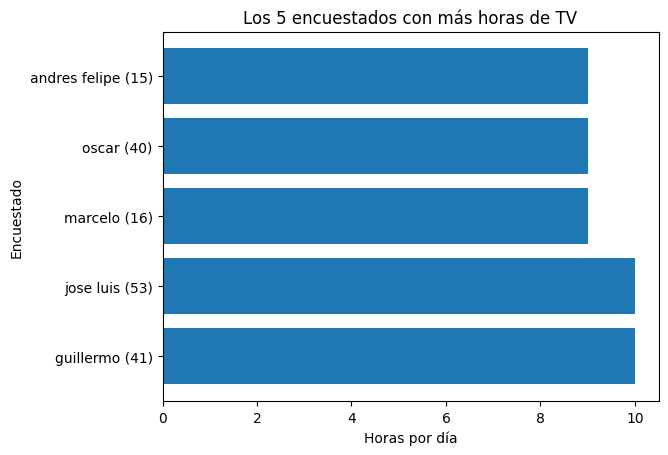

In [ ]:
# 1. Obtén las 5 filas con más 'horas' (nlargest).
# 2. Grafica con plt.barh(etiquetas, valores).
# 3. Reto: usa "nombre (edad)" como etiqueta; luego verás por qué (ver E6.3).
#    Pista: top5['nombre'] + ' (' + top5['edad'].astype(str) + ')'
top5_horas = df.nlargest(5, 'horas')
etiquetas = top5_horas['nombre'] + ' (' + top5_horas['edad'].astype(str) + ')'
plt.barh(etiquetas, top5_horas['horas'])
plt.title('Los 5 encuestados con más horas de TV')
plt.xlabel('Horas por día')
plt.ylabel('Encuestado')
plt.show()

### Evaluación — Parte 6

- **E6.1 (conceptual + código).** En el Paso 19, ¿qué ocurre con el 5.º lugar? Cuenta cuántas personas pagan lo mismo que quien quedó en el 5.º puesto. Investiga el parámetro `keep='all'` de `nlargest`.


**Respuesta:** El 5.º lugar tiene un costo de 24.000 y hay 9 personas que pagan eso, pero `nlargest(5)` solo muestra una parte de ellas y deja las demás por fuera de forma arbitraria. Con `keep='all'` aparecen todas las personas empatadas.

In [ ]:
quinto = df.nlargest(5, 'costo_mes')['costo_mes'].min()
print((df['costo_mes'] == quinto).sum())
df.nlargest(5, 'costo_mes', keep='all')

9


,nombre,edad,genero,canal_fav1,canal_fav2,canal_fav3,horas,costo_mes,grupo_edad
48,jose luis,53,M,ESPN,Fox Sports,NaN,10,27000,51-60
0,orlando,35,M,RCN,Telepacifico,HBO+,4,25000,31-40
5,guillermo,41,M,ESPN,ESPN2,Fox Sports,10,25000,41-50
16,oscar,40,M,Fox,ESPN,ESPN2,9,25000,31-40
10,carlos,37,M,ESPN,ESPN2,Fox Sports,6,24000,31-40
18,daniel,30,M,ESPN,ESPN2,Fox Sports,5,24000,21-30
24,rodrigo,38,M,ESPN,Fox Sports,GolTV,7,24000,31-40
33,carolina,44,F,HBO+,Netflix,Amazon Prime,5,24000,41-50
37,margarita,47,F,HBO+,Netflix,Amazon Prime,5,24000,41-50
41,carlos enrique,49,M,ESPN,Fox Sports,GolTV,7,24000,41-50


- **E6.2 (código).** ¿Cuántas personas hay en cada grupo de edad del Paso 20? ¿Por qué importa saberlo antes de interpretar los promedios?


In [ ]:
df['grupo_edad'].value_counts().sort_index()
# Grupos: 10-20: 15, 21-30: 23, 31-40: 17, 41-50: 10, 51-60: 3. Importa porque un promedio de solo 3 personas (51-60) es poco confiable.

,count
grupo_edad,
10-20,15
21-30,23
31-40,17
41-50,10
51-60,3


- **E6.3 (conceptual).** En el Paso 23 aparece el nombre `andres felipe`. ¿Qué problema puede causar usar `nombre` como etiqueta?


**Respuesta:** Hay dos personas distintas con el nombre andres felipe (una de 15 y otra de 36 años). Si se usa solo el nombre como etiqueta no se pueden diferenciar y el gráfico confunde. Es mejor usar nombre y edad, o un identificador único.

- **E6.4 (conceptual).** El costo promedio crece con el grupo de edad. ¿Puedes concluir que "envejecer hace que la gente gaste más en suscripciones"? Relaciónalo con E4.3.


**Respuesta:** No. En E4.3 la correlación entre edad y costo es 0.65, pero correlación no implica causalidad. Pueden influir otros factores (como los ingresos o si la persona paga por sí misma). Además hay grupos muy desiguales (el de 51-60 solo tiene 3 personas).

## Parte 7 — Análisis crítico: diferencias, asociaciones y outliers (Pasos 21, 24, 25)

Esta es la parte donde pasas de **describir** a **argumentar**. Aquí un número solo no basta: hay que preguntarse si es *grande*, si es *confiable* y si es *justo* compararlo.

> **Teoría — prueba de hipótesis en una línea.** Para comparar dos grupos se plantea:
> - **H₀:** no hay diferencia real entre los grupos (lo observado es azar).
> - **H₁:** sí hay diferencia.
>
> La prueba entrega un **p-valor**: la probabilidad de observar una diferencia *al menos tan grande* si H₀ fuera cierta. Si `p < 0.05` (nivel de significancia habitual) se rechaza H₀. **Un p-valor pequeño no dice que la diferencia sea importante, solo que es poco probable que sea azar.**


### Paso 21. ¿Hay diferencias significativas en el costo mensual entre hombres y mujeres?


                mean          std  count
genero                                  
F       20393.939394  2060.633912     33
M       22485.714286  1868.806297     35


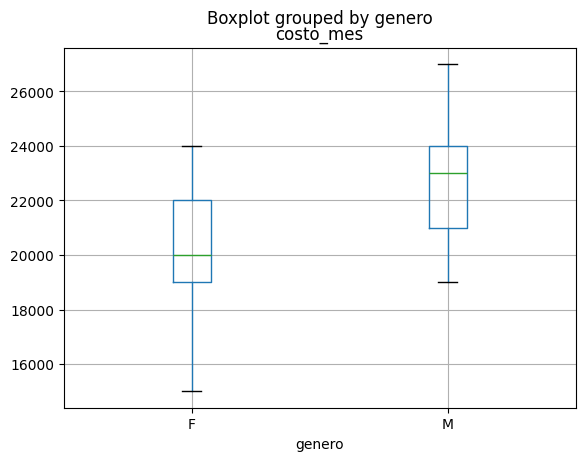

TtestResult(statistic=np.float64(4.376356607021125), pvalue=np.float64(4.516537285134966e-05), df=np.float64(64.41568433111847))


In [ ]:
# 1. Calcula media, desviación y cantidad de 'costo_mes' por género (groupby + agg).
# 2. Dibuja un diagrama de cajas por género: df.boxplot(column='costo_mes', by='genero')
# 3. Separa los costos en dos Series (hombres y mujeres).
# 4. Aplica la prueba t de Welch:
#       from scipy import stats
#       stats.ttest_ind(serie_a, serie_b, equal_var=False)
# 5. Escribe en un comentario tu conclusión usando el p-valor.
print(df.groupby('genero')['costo_mes'].agg(['mean', 'std', 'count']))
df.boxplot(column='costo_mes', by='genero')
plt.show()
hombres = df[df['genero'] == 'M']['costo_mes']
mujeres = df[df['genero'] == 'F']['costo_mes']
from scipy import stats
print(stats.ttest_ind(hombres, mujeres, equal_var=False))
# Conclusión: el p-valor es muy menor a 0.05, se rechaza H0. Hay diferencia significativa: los hombres pagan en promedio más que las mujeres.

### Paso 24. ¿Hay relación entre el género y los canales favoritos?

**Lógica:** una tabla de contingencia (`pd.crosstab`) cuenta cuántos hombres y mujeres eligieron cada canal. Si el género no importara, la proporción hombre/mujer sería parecida en todos los canales.


In [ ]:
# 1. Pasa los tres canales a formato largo con df.melt(...) y elimina los vacíos con .dropna(subset=['canal']).
# 2. Construye la tabla de contingencia canal x género.
# 3. Ordénala por total y observa los 10 canales más frecuentes.
# 4. (Opcional) Prueba chi-cuadrado: stats.chi2_contingency(tabla)
largo = df.melt(id_vars='genero', value_vars=['canal_fav1', 'canal_fav2', 'canal_fav3'], value_name='canal').dropna(subset=['canal'])
tabla = pd.crosstab(largo['canal'], largo['genero'])
tabla['total'] = tabla['F'] + tabla['M']
tabla = tabla.sort_values('total', ascending=False)
print(tabla.head(10))
print(stats.chi2_contingency(tabla[['F', 'M']]))

genero         F   M  total
canal                      
HBO+          16   9     25
Netflix       14   7     21
ESPN           2  13     15
RCN           11   4     15
Fox Sports     2  12     14
Amazon Prime   9   5     14
Caracol       11   3     14
Disney+        4   6     10
ESPN2          2   7      9
Discovery      4   4      8
Chi2ContingencyResult(statistic=np.float64(59.05044882586549), pvalue=np.float64(0.000350853016529403), dof=27, expected_freq=array([[12.19211823, 12.80788177],
       [10.24137931, 10.75862069],
       [ 7.31527094,  7.68472906],
       [ 7.31527094,  7.68472906],
       [ 6.82758621,  7.17241379],
       [ 6.82758621,  7.17241379],
       [ 6.82758621,  7.17241379],
       [ 4.87684729,  5.12315271],
       [ 4.38916256,  4.61083744],
       [ 3.90147783,  4.09852217],
       [ 3.4137931 ,  3.5862069 ],
       [ 2.92610837,  3.07389163],
       [ 2.92610837,  3.07389163],
       [ 2.43842365,  2.56157635],
       [ 2.43842365,  2.56157635],
       [ 2.43

> **Advertencia — chi-cuadrado con muestras pequeñas.** Esa prueba exige conteos esperados razonablemente grandes por celda. Con 28 canales y 68 personas, muchas celdas quedan casi vacías: toma el p-valor como **orientación exploratoria**, no como veredicto.


### Paso 25. Outliers en `horas` y `costo_mes` y su impacto

> **Teoría — dos reglas para detectar outliers.**
> - **Regla IQR:** `IQR = Q3 − Q1`. Es atípico lo que queda fuera de `[Q1 − 1.5·IQR , Q3 + 1.5·IQR]`. Es la regla que dibuja los "bigotes" del boxplot.
> - **Regla z:** `z = (x − media) / desviación`. Se sospecha de `|z| > 2` (o 3 en muestras grandes).
>
> *Atípico no significa erróneo.* Antes de eliminar, pregunta si es un error de captura o un caso real.


Empty DataFrame
Columns: [nombre, horas]
Index: []
  nombre  costo_mes
3  luisa      15000
       nombre  horas
5   guillermo     10
48  jose luis     10
       nombre  costo_mes
3       luisa      15000
48  jose luis      27000


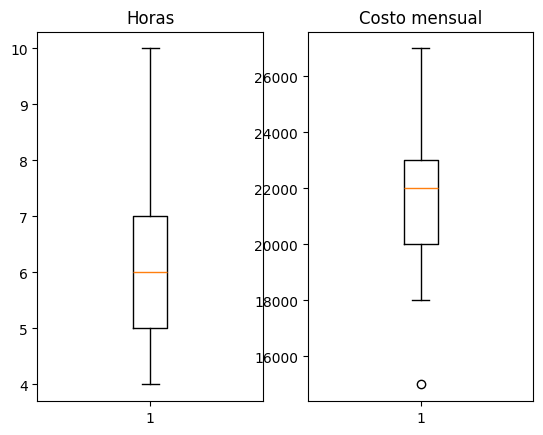

Con atípicos: 21470.58823529412 2215.754904782675
Sin atípicos: 21567.16417910448 2083.294888835697


In [ ]:
# 1. Escribe una función outliers_iqr(serie) que devuelva una máscara booleana con la regla IQR (use serie.quantile([0.25, 0.75])).
# 2. Aplícala a 'horas' y a 'costo_mes' y muestra quiénes son los atípicos.
# 3. Repite con la regla z.
# 4. Dibuja un boxplot de cada variable (dos subgráficos con plt.subplots(1, 2)).
# 5. Mide el impacto: compara la media y la desviación de 'costo_mes' con y sin los atípicos.
def outliers_iqr(serie):
    q1, q3 = serie.quantile([0.25, 0.75])
    iqr = q3 - q1
    return (serie < q1 - 1.5 * iqr) | (serie > q3 + 1.5 * iqr)

def outliers_z(serie):
    z = (serie - serie.mean()) / serie.std()
    return z.abs() > 2

# Regla IQR
print(df[outliers_iqr(df['horas'])][['nombre', 'horas']])
print(df[outliers_iqr(df['costo_mes'])][['nombre', 'costo_mes']])
# Regla z
print(df[outliers_z(df['horas'])][['nombre', 'horas']])
print(df[outliers_z(df['costo_mes'])][['nombre', 'costo_mes']])

# Boxplots
fig, ax = plt.subplots(1, 2)
ax[0].boxplot(df['horas'])
ax[0].set_title('Horas')
ax[1].boxplot(df['costo_mes'])
ax[1].set_title('Costo mensual')
plt.show()

# Impacto de los atípicos en costo_mes
sin_atipicos = df[~outliers_iqr(df['costo_mes'])]['costo_mes']
print('Con atípicos:', df['costo_mes'].mean(), df['costo_mes'].std())
print('Sin atípicos:', sin_atipicos.mean(), sin_atipicos.std())

### Evaluación — Parte 7

- **E7.1 (conceptual).** En el Paso 21 obtuviste un p-valor muy inferior a 0.05. Explica con tus palabras qué significa y qué **no** significa.


**Respuesta:** El p-valor (4.5e-05) es mucho menor que 0.05, por lo que se rechaza H₀: es muy poco probable que la diferencia de costo entre hombres y mujeres sea solo azar. No significa que la diferencia sea grande o importante, ni que el género sea la causa del mayor gasto.

- **E7.2 (código + conceptual).** Calcula la **edad promedio por género**. Sabiendo que la edad correlaciona con el costo (E4.3), ¿qué advertencia harías sobre la conclusión del Paso 21?


In [ ]:
df.groupby('genero')['edad'].mean()

,edad
genero,
F,28.212121
M,31.457143


**Respuesta:** Los hombres tienen mayor edad promedio (31.5 años) que las mujeres (28.2 años). Como la edad se relaciona con el costo (0.65), la diferencia del Paso 21 podría deberse a la edad y no al género. Hay que tener cuidado con esa conclusión.

- **E7.3 (código).** Calcula la media y desviación de `costo_mes` **sin** los outliers detectados por la regla z. ¿Cuánto cambian?


In [ ]:
sin_z = df[~outliers_z(df['costo_mes'])]['costo_mes']
print('Sin atípicos (z):', sin_z.mean(), sin_z.std())
print('Con todos los datos:', df['costo_mes'].mean(), df['costo_mes'].std())
# Sin atípicos (z) la media casi no cambia (21.471 a 21.485) y la desviación baja un poco (2.216 a 1.986).

Sin atípicos (z): 21484.848484848484 1986.4341786026414
Con todos los datos: 21470.58823529412 2215.754904782675


- **E7.4 (conceptual).** ¿Es correcto eliminar automáticamente a los outliers? Da un argumento a favor y uno en contra.


**Respuesta:** A favor: los atípicos pueden distorsionar la media y la desviación, y si son errores de captura conviene quitarlos. En contra: pueden ser casos reales e importantes (por ejemplo, quienes más pagan), y al eliminarlos automáticamente se pierde información.

## Conclusión

Redacta, en un máximo de **5 líneas** y sin usar código, las conclusiones que presentarías a la gerencia del canal: *quién ve qué, cuánto ve y cuánto paga*. Para cada afirmación, indica el **paso** del que proviene y una **limitación** (por ejemplo: muestra de solo 68 personas, posibles errores de captura, grupos de edad desbalanceados).


1. **Quién ve qué:** HBO+ y Netflix son los más mencionados; mujeres prefieren HBO+ y hombres ESPN (Pasos 10-11). Limitación: solo 68 personas.
2. **Cuánto ve:** 6.1 horas al día en promedio, sin relación lineal con la edad (Paso 12). Limitación: muestra pequeña.
3. **Cuánto paga:** $21.471 al mes en promedio y los hombres pagan más (Pasos 13 y 21). Limitación: los hombres son mayores y el grupo de 51-60 tiene solo 3 personas.
4. **Atípicos:** son pocos y casi no cambian el promedio (Paso 25). Limitación: pueden existir errores de captura.